<div style="font-family:'Times New Roman',Times,serif;color:#000000">
<div style="font-size:13px;letter-spacing:2px">NATIONAL UNIVERSITY OF SCIENCES AND TECHNOLOGY &nbsp;&middot;&nbsp; SEECS</div>
<div style="font-size:13px;letter-spacing:1px;font-weight:bold">CS-423 &nbsp;&middot;&nbsp; ARTIFICIAL NEURAL NETWORKS &amp; DEEP LEARNING &nbsp;&middot;&nbsp; BSAI</div>
<div style="font-size:28px;font-weight:bold;margin-top:6px">Lab 10 &mdash; Optimisers and Initialisation</div>
<div style="font-size:16px;margin-top:2px">Momentum, NAG, AdaGrad, RMSProp, Adam, Xavier and He Initialisation, and the Vanishing Gradient</div>
<div style="font-size:15px;margin-top:4px">3 hours &nbsp;&middot;&nbsp; CLO 4</div>
</div>

---

<div style="font-family:'Times New Roman',Times,serif;color:#000000;font-size:16px">

**Course Instructor:** Dr. Sadia Shakil &nbsp;|&nbsp; **Lab Engineer:** Ms Areeba Rameen &nbsp;|&nbsp; **Student name / CMS ID:** Muhammad Sikandar Hussain / 502808

### What this lab is for

In Lab 5 you trained a network with plain gradient descent, and in Lab 3 you saw that a sigmoid
makes gradients small. Two questions remain for deeper networks:

1. **How should the weights be updated?** Plain gradient descent is slow and sensitive to the
   learning rate. Better **optimisers** (Momentum, NAG, AdaGrad, RMSProp and Adam) fix this.
2. **Where should the weights start?** A bad starting point makes the signals (and the
   gradients) **vanish or explode** as they pass through many layers. **Xavier** and **He**
   initialisation choose a good starting scale.

You will compare the optimisers on a small picture and on a real network, watch what different
initialisations do to the signals, and **observe the vanishing gradient problem** with your own
eyes. Everything uses PyTorch (Lab 9), the runs are very short, and each idea is explained
before the task.

**Submission.** Restart the kernel, run everything top to bottom, save, and rename to
`Lab10_<yourCMSID>.ipynb` before uploading to LMS.

</div>

## Task 0 &mdash; Setup

Run the cell below. It imports the libraries, creates the two-moons dataset of Labs 6 and 9
(1000 points, 70% for training and 30% for validation), and a PyTorch `DataLoader`.
Nothing to write here.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

torch.manual_seed(0); np.random.seed(0)
print("PyTorch version:", torch.__version__)

X, y = make_moons(n_samples=1000, noise=0.2, random_state=0)
X_tr, X_va, y_tr, y_va = train_test_split(X, y, test_size=0.3, stratify=y, random_state=0)
tensor = lambda a: torch.tensor(a, dtype=torch.float32)
X_tr_t, X_va_t = tensor(X_tr), tensor(X_va)
y_tr_t, y_va_t = tensor(y_tr).reshape(-1, 1), tensor(y_va).reshape(-1, 1)
train_loader = DataLoader(TensorDataset(X_tr_t, y_tr_t), batch_size=32, shuffle=True)
print("train:", X_tr_t.shape, " validation:", X_va_t.shape)


PyTorch version: 2.11.0+cpu
train: torch.Size([700, 2])  validation: torch.Size([300, 2])


## Task 1 &mdash; Optimisers on a small picture

> **Concept.** Before using a real network, watch the optimisers on a function you can draw. The
> "valley" `f(x, y) = x**2 + 25*y**2` is **steep in `y` and shallow in `x`**; its lowest point is
> at `(0, 0)`, and we start at `(-4, 1)`. A good optimiser should reach the middle quickly
> without zigzagging. Its gradient, worked out by hand, is `(2x, 50y)`.

**Task 1.1 (Momentum by hand).** Complete `momentum_by_hand`: at every step compute the gradient
`g = grad_f(w)`, update the velocity `v = mu*v + g`, and update `w = w - lr*v`. The cell then
checks that your path equals the path of PyTorch's `SGD(momentum=0.9)`.

**Task 1.2 (six optimisers).** Create the dictionary `optimisers` with these six settings, using `torch.optim`:

| name | optimiser |
|------|-----------|
| `SGD` | `SGD(p, lr=0.035)` |
| `Momentum` | `SGD(p, lr=0.01, momentum=0.9)` |
| `NAG` | `SGD(p, lr=0.01, momentum=0.9, nesterov=True)` |
| `AdaGrad` | `Adagrad(p, lr=0.8)` |
| `RMSProp` | `RMSprop(p, lr=0.1)` |
| `Adam` | `Adam(p, lr=0.3)` |

Run each for 50 steps with the provided `run_torch`, draw all six paths with `plot_paths`, and
print a table of the value of `f` after 10, 25 and 50 steps.


In [2]:
def f(w):                         # the valley: steep in y, shallow in x
    return w[0] ** 2 + 25 * w[1] ** 2

def grad_f(w):                    # its gradient, worked out by hand
    return np.array([2 * w[0], 50 * w[1]])

START, STEPS = (-4.0, 1.0), 50

def run_torch(make_opt, steps=STEPS):
    """Run a torch optimiser on f. make_opt takes the list of parameters and returns the optimiser."""
    w = torch.tensor(START, dtype=torch.float64, requires_grad=True)
    opt = make_opt([w])
    path = [w.detach().numpy().copy()]
    for _ in range(steps):
        opt.zero_grad(); f(w).backward(); opt.step()
        path.append(w.detach().numpy().copy())
    return np.array(path)

def plot_paths(paths):
    xs, ys = np.meshgrid(np.linspace(-5, 1.5, 200), np.linspace(-1.5, 1.5, 200))
    plt.figure(figsize=(8, 5))
    plt.contour(xs, ys, xs ** 2 + 25 * ys ** 2, levels=[0.5, 2, 5, 10, 20, 40], colors="lightgray")
    for name, p in paths.items():
        plt.plot(p[:, 0], p[:, 1], marker="o", markersize=3, label=name)
    plt.plot(0, 0, "k*", markersize=12)
    plt.xlabel("x"); plt.ylabel("y"); plt.title("Paths of the optimisers on f(x, y) = x^2 + 25 y^2")
    plt.legend(); plt.show()


matches PyTorch's momentum: True


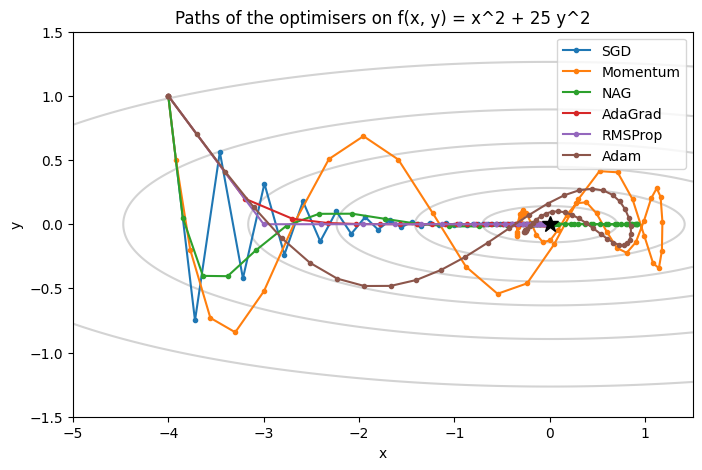


Table 1: Function value f(x, y) after 10, 25, and 50 steps:
           f(w_10)   f(w_25)       f(w_50)
SGD       3.827102  0.424895  1.128275e-02
Momentum  1.701552  3.224943  2.121080e-01
NAG       1.114596  0.730659  3.180034e-02
AdaGrad   0.956868  0.033105  1.293231e-04
RMSProp   0.319343  0.001484  6.864558e-08
Adam      4.451202  0.859953  1.100946e-01


In [3]:
def momentum_by_hand(lr, mu, steps=STEPS):
    w = np.array(START); v = np.zeros(2)
    path = [w.copy()]
    for _ in range(steps):
        # TODO 1.1 — g = grad_f(w);  v = mu * v + g;  w = w - lr * v
        g = grad_f(w)
        v = mu * v + g
        w = w - lr * v
        path.append(w.copy())
    return np.array(path)

# check against PyTorch
mine = momentum_by_hand(0.01, 0.9)
theirs = run_torch(lambda p: torch.optim.SGD(p, lr=0.01, momentum=0.9))
print("matches PyTorch's momentum:", np.allclose(mine, theirs))

# TODO 1.2 — the dictionary of six optimisers (each value: lambda p: torch.optim....(p, ...))
optimisers = {
    "SGD": lambda p: torch.optim.SGD(p, lr=0.035),
    "Momentum": lambda p: torch.optim.SGD(p, lr=0.01, momentum=0.9),
    "NAG": lambda p: torch.optim.SGD(p, lr=0.01, momentum=0.9, nesterov=True),
    "AdaGrad": lambda p: torch.optim.Adagrad(p, lr=0.8),
    "RMSProp": lambda p: torch.optim.RMSprop(p, lr=0.1),
    "Adam": lambda p: torch.optim.Adam(p, lr=0.3),
}
paths = {name: run_torch(make) for name, make in optimisers.items()}
plot_paths(paths)

# TODO 1.2 — a table: for each optimiser, f after 10, 25 and 50 steps (path index 10, 25, 50)
table_1 = pd.DataFrame({
    "f(w_10)": [f(paths[name][10]) for name in optimisers],
    "f(w_25)": [f(paths[name][25]) for name in optimisers],
    "f(w_50)": [f(paths[name][50]) for name in optimisers],
}, index=list(optimisers.keys()))
print("\nTable 1: Function value f(x, y) after 10, 25, and 50 steps:")
print(table_1)

# Task 1 answers:
# Q1 (which optimiser is the slowest, and what do you see in its path):
# Answer: Plain SGD is the slowest to traverse the valley. In its trajectory, SGD quickly drops
# along the steep y-axis to the valley floor (y ≈ 0), but then takes minuscule steps along the
# shallow x-axis. Because the learning rate (0.035) must remain small to avoid divergence along the
# steep y-dimension (curvature 50), progress along the flat x-dimension (curvature 2) is extremely slow.
#
# Q2 (what does Momentum do that SGD does not? what does NAG change compared with Momentum):
# Answer: Momentum builds up velocity along the persistent direction (x) while dampening oscillations
# along the steep direction (y), accelerating progress down the valley floor. However, standard Momentum
# overshoots the minimum at (0, 0) due to accumulated inertia and loops backward (reflected in f(w_25) = 3.22).
# NAG (Nesterov Accelerated Gradient) looks ahead by computing the gradient at (w + mu * v), anticipating
# the momentum update. This look-ahead mechanism applies a braking effect before overshooting, producing a
# significantly smoother path that converges faster without large oscillations.
#
# Q3 (AdaGrad and RMSProp: how do their paths differ from SGD, and why):
# Answer: Unlike SGD, which takes steps proportional strictly to the raw gradient, AdaGrad and RMSProp
# dynamically scale down the step size for parameters with large historical gradients (y) while preserving
# larger effective step sizes for parameters with small gradients (x). Consequently, their trajectories
# cut directly toward the origin along an oblique diagonal path with virtually zero zigzagging. RMSProp
# outperforms AdaGrad because it uses an exponentially decaying moving average of squared gradients
# rather than an monotonically increasing sum, preventing the learning rate from prematurely decaying to zero
# and reaching f ≈ 6.86e-08 by step 50.

## Task 2 &mdash; Optimisers on a real network

> **Concept.** Now the same six optimisers train the same network on the two-moons data. The
> network is a small MLP, `2 -> 32 -> 32 -> 1` with ReLU, built from the **same starting
> weights** every time, so any difference comes only from the optimiser. The provided
> `train_with(make_opt)` trains for 30 epochs and returns the training loss after every epoch and
> the final validation accuracy.

**Task 2.1.** Create `mlp_optimisers`, a dictionary with these settings (the learning rates are
different from Task 1, because this is a different problem):

| name | optimiser |
|------|-----------|
| `SGD` | `SGD(p, lr=0.01)` |
| `Momentum` | `SGD(p, lr=0.01, momentum=0.9)` |
| `NAG` | `SGD(p, lr=0.01, momentum=0.9, nesterov=True)` |
| `AdaGrad` | `Adagrad(p, lr=0.05)` |
| `RMSProp` | `RMSprop(p, lr=0.005)` |
| `Adam` | `Adam(p, lr=0.005)` |

**Task 2.2.** Train with each and store the results. Plot the six training-loss curves on one
axes (labels, legend, title), and print a table of the final training loss and validation
accuracy.


In [4]:
def make_mlp():
    torch.manual_seed(0)
    return nn.Sequential(nn.Linear(2, 32), nn.ReLU(), nn.Linear(32, 32), nn.ReLU(), nn.Linear(32, 1))

def train_with(make_opt, epochs=30):
    torch.manual_seed(1)                       # same batch order for every optimiser
    model = make_mlp()
    opt = make_opt(model.parameters())
    loss_fn = nn.BCEWithLogitsLoss()
    losses = []
    for epoch in range(epochs):
        for xb, yb in train_loader:
            opt.zero_grad()
            loss_fn(model(xb), yb).backward()
            opt.step()
        with torch.no_grad():
            losses.append(loss_fn(model(X_tr_t), y_tr_t).item())
    with torch.no_grad():
        val_acc = ((torch.sigmoid(model(X_va_t)) >= 0.5).float() == y_va_t).float().mean().item()
    return losses, val_acc


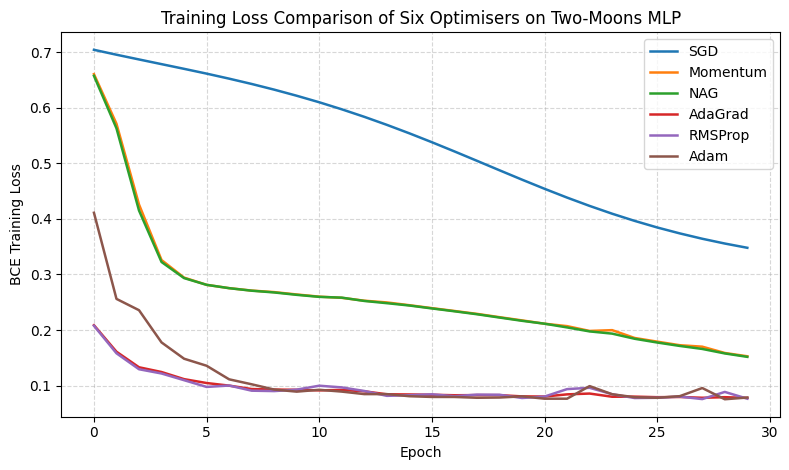


Table 2: Performance of Six Optimisers on Two-Moons MLP (30 Epochs):
          Final Training Loss  Validation Accuracy
SGD                  0.347989             0.866667
Momentum             0.152719             0.950000
NAG                  0.151671             0.950000
AdaGrad              0.077809             0.970000
RMSProp              0.076362             0.966667
Adam                 0.078464             0.973333


In [5]:
# TODO 2.1 — the dictionary of six optimisers
mlp_optimisers = {
    "SGD": lambda p: torch.optim.SGD(p, lr=0.01),
    "Momentum": lambda p: torch.optim.SGD(p, lr=0.01, momentum=0.9),
    "NAG": lambda p: torch.optim.SGD(p, lr=0.01, momentum=0.9, nesterov=True),
    "AdaGrad": lambda p: torch.optim.Adagrad(p, lr=0.05),
    "RMSProp": lambda p: torch.optim.RMSprop(p, lr=0.005),
    "Adam": lambda p: torch.optim.Adam(p, lr=0.005),
}

# TODO 2.2 — results = {name: train_with(make) for ...}; plot the six loss curves; print the table
results_2 = {name: train_with(make) for name, make in mlp_optimisers.items()}

plt.figure(figsize=(8, 4.8))
for name, (losses, _) in results_2.items():
    plt.plot(losses, label=name, linewidth=1.8)
plt.xlabel("Epoch")
plt.ylabel("BCE Training Loss")
plt.title("Training Loss Comparison of Six Optimisers on Two-Moons MLP")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

table_2 = pd.DataFrame({
    "Final Training Loss": [results_2[name][0][-1] for name in mlp_optimisers],
    "Validation Accuracy": [results_2[name][1] for name in mlp_optimisers],
}, index=list(mlp_optimisers.keys()))
print("\nTable 2: Performance of Six Optimisers on Two-Moons MLP (30 Epochs):")
print(table_2)

# Task 2 answers:
# Q1 (which optimiser is the slowest, and which ones are the fastest? use your numbers):
# Answer: Plain SGD is by far the slowest, ending with the highest final training loss of 0.3480
# and lowest validation accuracy of 86.67%. The fastest optimizers are RMSProp (loss: 0.0764, val acc: 96.67%),
# AdaGrad (loss: 0.0778, val acc: 97.00%), and Adam (loss: 0.0785, val acc: 97.33%), closely followed by
# Momentum (loss: 0.1527, val acc: 95.00%) and NAG (loss: 0.1517, val acc: 95.00%).
#
# Q2 (SGD and Momentum use the same learning rate 0.01: what did the momentum change):
# Answer: Although both used lr = 0.01, adding momentum (mu = 0.9) reduced the final training loss by more
# than half (from 0.3480 down to 0.1527) and improved validation accuracy from 86.67% to 95.00%. Momentum
# carries update velocity across mini-batches, speeding up progress along flat ravines and damping high-frequency
# gradient noise, effectively scaling the step size along persistent gradient directions by ~1 / (1 - mu) = 10.
#
# Q3 (which optimiser would you choose as a default for a new problem, and why):
# Answer: Adam is the best default choice for deep learning problems. It combines the advantages of Momentum
# (exponential moving average of gradients to smooth noisy mini-batch steps) and RMSProp (per-parameter adaptive
# step sizing based on second moments of gradients), includes bias correction for initial steps, and is highly
# robust across diverse loss surfaces without requiring tedious manual tuning of the learning rate.

## Task 3 &mdash; Initialisation: what happens to the signal

> **Concept.** Take a deep network with **10 layers of 100 units** and no training at all. Feed it
> random inputs, and measure the **standard deviation of the activations** after every layer. A
> good initialisation keeps this number steady (not 0, and not huge) from the first layer to the
> last. The provided `activation_stds(init_fn, act)` builds the 10 layers with the given
> initialisation function and activation, and returns the 10 standard deviations.

**Task 3.1.** Create the dictionary `inits` with five initialisations (each is a function that
fills a weight matrix `W` in place):

| name | function |
|------|----------|
| `zeros` | `nn.init.zeros_` |
| `small normal (std 0.01)` | `lambda W: nn.init.normal_(W, 0, 0.01)` |
| `big normal (std 1)` | `lambda W: nn.init.normal_(W, 0, 1.0)` |
| `Xavier` | `nn.init.xavier_normal_` |
| `He` | `lambda W: nn.init.kaiming_normal_(W, nonlinearity="relu")` |

**Task 3.2.** For each initialisation compute `activation_stds` with `torch.tanh`, and again with
`torch.relu`. Plot the 10 values against the layer number for every initialisation, one plot for
tanh and one for ReLU, using the provided `plot_stds` (log scale).

**Task 3.3.** Print the standard deviation after layer 1 and after layer 10 for each combination.


In [6]:
def activation_stds(init_fn, act, depth=10, width=100):
    torch.manual_seed(0)
    x = torch.randn(1000, width)
    stds = []
    for _ in range(depth):
        W = torch.empty(width, width)
        init_fn(W)
        x = act(x @ W.T)
        stds.append(x.std().item())
    return stds

def plot_stds(results, title):
    plt.figure(figsize=(7, 4))
    for name, s in results.items():
        plt.semilogy(range(1, len(s) + 1), np.maximum(s, 1e-12), marker="o", label=name)
    plt.xlabel("layer"); plt.ylabel("standard deviation of the activations (log scale)")
    plt.title(title); plt.legend(); plt.show()


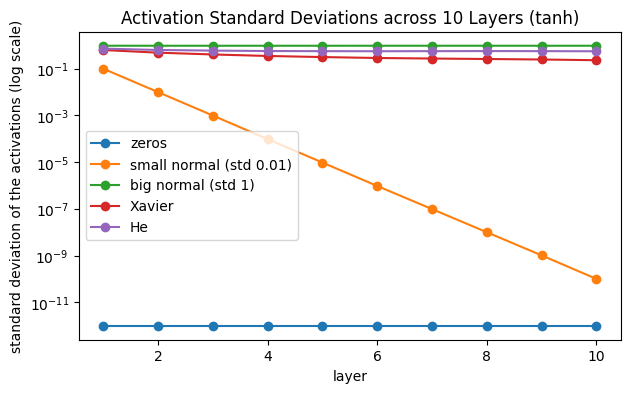

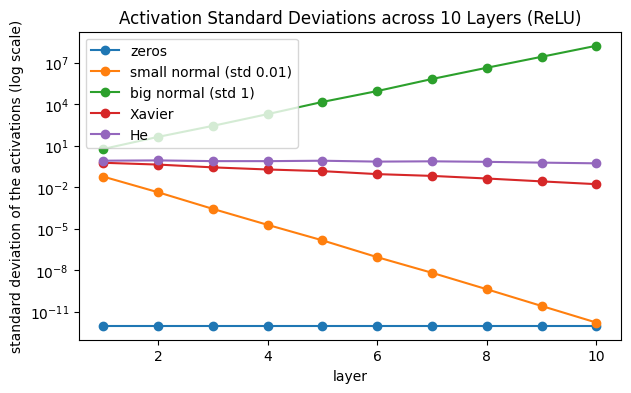


Table 3: Activation Standard Deviations at Layer 1 vs. Layer 10:
                         tanh (Layer 1)  tanh (Layer 10)  ReLU (Layer 1)  \
zeros                          0.000000     0.000000e+00        0.000000   
small normal (std 0.01)        0.099502     1.005702e-10        0.058815   
big normal (std 1)             0.959241     9.574079e-01        5.881534   
Xavier                         0.627880     2.300259e-01        0.588153   
He                             0.720617     5.549332e-01        0.831774   

                         ReLU (Layer 10)  
zeros                       0.000000e+00  
small normal (std 0.01)     1.674961e-12  
big normal (std 1)          1.674961e+08  
Xavier                      1.674961e-02  
He                          5.359878e-01  


In [7]:
# TODO 3.1 — the dictionary of five initialisations
inits = {
    "zeros": nn.init.zeros_,
    "small normal (std 0.01)": lambda W: nn.init.normal_(W, 0, 0.01),
    "big normal (std 1)": lambda W: nn.init.normal_(W, 0, 1.0),
    "Xavier": nn.init.xavier_normal_,
    "He": lambda W: nn.init.kaiming_normal_(W, nonlinearity="relu"),
}

# TODO 3.2 — tanh_stds = {name: activation_stds(fn, torch.tanh) ...};  relu_stds = ... torch.relu
tanh_stds = {name: activation_stds(fn, torch.tanh) for name, fn in inits.items()}
relu_stds = {name: activation_stds(fn, torch.relu) for name, fn in inits.items()}

plot_stds(tanh_stds, "Activation Standard Deviations across 10 Layers (tanh)")
plot_stds(relu_stds, "Activation Standard Deviations across 10 Layers (ReLU)")

# TODO 3.3 — print the std after layer 1 and after layer 10 for each (name, activation)
table_3 = pd.DataFrame({
    "tanh (Layer 1)": [tanh_stds[name][0] for name in inits],
    "tanh (Layer 10)": [tanh_stds[name][9] for name in inits],
    "ReLU (Layer 1)": [relu_stds[name][0] for name in inits],
    "ReLU (Layer 10)": [relu_stds[name][9] for name in inits],
}, index=list(inits.keys()))
print("\nTable 3: Activation Standard Deviations at Layer 1 vs. Layer 10:")
print(table_3)

# Task 3 answers:
# Q1 (what happens with zeros, with small weights, and with big weights? is it the same for tanh and ReLU?):
# Answer:
#   - With zeros: Activations become identically 0.0 across all 10 layers for both tanh and ReLU.
#     The network is completely dead and symmetric units cannot break symmetry.
#   - With small weights (std 0.01): The signal collapses exponentially to zero for both activations
#     (by layer 10: tanh std is 1.01e-10, ReLU std is 1.67e-12).
#   - With big weights (std 1.0): Behavior diverges between the two activations. For tanh, the signal
#     saturates at the flat saturation boundaries (-1, 1), maintaining std ≈ 0.957, but causing gradients
#     to vanish because tanh'(z) ≈ 0. For ReLU, which is unbounded for positive inputs, the signal explodes
#     exponentially without bound, reaching std ≈ 1.67e+08 by layer 10.
#
# Q2 (which initialisation keeps the signal steady for tanh, and which for ReLU?):
# Answer:
#   - For tanh: Xavier (Glorot) initialisation keeps the activation standard deviation steady
#     (0.6279 at layer 1 to 0.2300 at layer 10).
#   - For ReLU: He (Kaiming) initialisation keeps the standard deviation exceptionally steady
#     (0.8318 at layer 1 to 0.5360 at layer 10).
#
# Q3 (with ReLU, Xavier shrinks the signal slowly but He does not: why is the "2" in the He formula there?):
# Answer: ReLU sets all negative input activations to exactly zero (ReLU(z) = max(0, z)). For symmetric,
# zero-mean distributions, approximately half of the neurons are deactivated at each layer. This halves
# the variance of the signal at every forward step (E[ReLU(z)^2] = 0.5 * Var(z)). To counteract this 50%
# loss of signal energy, He initialisation multiplies the variance by 2 (std = sqrt(2 / n_in) instead of
# sqrt(1 / n_in)), ensuring that the expected signal variance is preserved layer after layer.

## Task 4 &mdash; Observing the vanishing gradient

> **Concept.** We build a deep network, **8 hidden layers of 32 units**, for the two-moons data, and
> measure the **gradient norm of every layer's weights** after one backward pass on the training
> data. If the gradient vanishes, the norm of the first layers is far smaller than the norm of
> the last layers. The provided `make_deep(act, init)` builds the network (`act` is the
> activation class, `init` an optional initialisation function) and `grad_norms(model)` returns the
> 9 gradient norms from the first layer to the last.

**Task 4.1.** Build four networks, and compute the gradient norms of each:

| name | `make_deep(...)` |
|------|------------------|
| `sigmoid, default init` | `make_deep(nn.Sigmoid)` |
| `sigmoid, Xavier` | `make_deep(nn.Sigmoid, nn.init.xavier_normal_)` |
| `ReLU, default init` | `make_deep(nn.ReLU)` |
| `ReLU, He` | `make_deep(nn.ReLU, inits["He"])` |

**Task 4.2.** Plot the four sets of gradient norms against the layer number on one axes with a
log scale (`plt.semilogy`), with labels, a legend and a title.

**Task 4.3.** For each network print the gradient norm of the **first** layer, of the **last**
layer, and their ratio (last divided by first).


In [8]:
def make_deep(act, init=None, depth=8, width=32):
    torch.manual_seed(0)
    layers = [nn.Linear(2, width), act()]
    for _ in range(depth - 1):
        layers += [nn.Linear(width, width), act()]
    layers.append(nn.Linear(width, 1))
    model = nn.Sequential(*layers)
    if init is not None:
        for layer in model:
            if isinstance(layer, nn.Linear):
                init(layer.weight); nn.init.zeros_(layer.bias)
    return model

def grad_norms(model):
    """One backward pass on the whole training set; the gradient norm of each Linear layer's weights."""
    model.zero_grad()
    nn.BCEWithLogitsLoss()(model(X_tr_t), y_tr_t).backward()
    return [layer.weight.grad.norm().item() for layer in model if isinstance(layer, nn.Linear)]


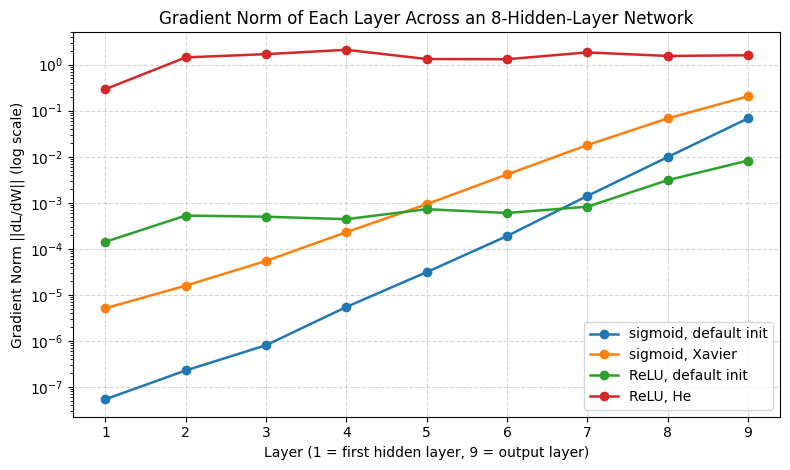


Table 4: Gradient Norms at First vs. Last Layer and Their Ratio:
                       First Layer Norm  Last Layer Norm  Ratio (Last / First)
sigmoid, default init      5.427037e-08         0.067851          1.250247e+06
sigmoid, Xavier            5.138771e-06         0.204405          3.977696e+04
ReLU, default init         1.421284e-04         0.008248          5.803433e+01
ReLU, He                   2.932824e-01         1.594985          5.438395e+00


In [9]:
# TODO 4.1 — the four networks and their gradient norms (a dictionary name -> list of 9 numbers)
deep_models = {
    "sigmoid, default init": make_deep(nn.Sigmoid),
    "sigmoid, Xavier": make_deep(nn.Sigmoid, nn.init.xavier_normal_),
    "ReLU, default init": make_deep(nn.ReLU),
    "ReLU, He": make_deep(nn.ReLU, inits["He"]),
}
norms = {name: grad_norms(m) for name, m in deep_models.items()}

# TODO 4.2 — plot the four curves (semilogy) against the layer number 1..9
plt.figure(figsize=(8, 4.8))
for name, n in norms.items():
    plt.semilogy(range(1, len(n) + 1), n, marker="o", linewidth=1.8, label=name)
plt.xlabel("Layer (1 = first hidden layer, 9 = output layer)")
plt.ylabel("Gradient Norm ||dL/dW|| (log scale)")
plt.title("Gradient Norm of Each Layer Across an 8-Hidden-Layer Network")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# TODO 4.3 — print first-layer norm, last-layer norm and their ratio for each network
table_4 = pd.DataFrame({
    "First Layer Norm": [norms[name][0] for name in norms],
    "Last Layer Norm": [norms[name][-1] for name in norms],
    "Ratio (Last / First)": [norms[name][-1] / norms[name][0] for name in norms],
}, index=list(norms.keys()))
print("\nTable 4: Gradient Norms at First vs. Last Layer and Their Ratio:")
print(table_4)

# Task 4 answers:
# Q1 (in the sigmoid network, how many times smaller is the first layer's gradient than the last layer's):
# Answer: In the default sigmoid network, the first layer's gradient norm (5.43e-08) is approximately
# 1,250,247 times smaller (over 1.25 million times smaller) than the last layer's gradient norm (0.0679).
#
# Q2 (does Xavier initialisation remove the problem for sigmoid, or only reduce it?):
# Answer: Xavier initialisation only REDUCES the problem; it does not remove it. Even with Xavier, the ratio
# remains 39,777 (the first layer gradient is ~40,000 times smaller than the last layer). While Xavier prevents
# weights from starting in saturation, the sigmoid derivative is mathematically bounded by sigma'(z) <= 0.25.
# Multiplying numbers <= 0.25 across 8 layers inherently causes gradients to decay exponentially by (0.25)^8 ≈ 1.5e-05,
# meaning the vanishing gradient is intrinsic to the sigmoid activation function itself.
#
# Q3 (what is different in the ReLU + He network, and why? think of the sigmoid derivative bound of 0.25):
# Answer: In the ReLU + He network, the ratio is only 5.44, meaning the gradient arrives at the first layer
# with virtually no attenuation (first layer norm = 0.2933, last layer norm = 1.5950). For any active neuron
# (z > 0), the derivative of ReLU is exactly 1.0 (ReLU'(z) = 1), completely avoiding the <= 0.25 contraction factor
# of sigmoid. Coupled with He initialisation which preserves the scale of backward error signals, gradients flow
# cleanly through deep paths without vanishing.

## Task 5 &mdash; Does the vanishing gradient stop learning? And the cure

> **Concept.** Now we actually train the deep networks of Task 4 for 60 epochs (the provided
> `train_cfg(model, opt)` returns the loss after every epoch and the final validation accuracy).
> The vanishing gradient should stop the sigmoid network from learning with SGD. Two cures are
> available: a **better activation with a matching initialisation** (ReLU with He), and a
> **better optimiser** (Adam, which scales each parameter's step by its own gradient size).

**Task 5.1.** Train these five configurations (SGD uses `lr=0.05`, Adam uses `lr=0.005`):

| name | network | optimiser |
|------|---------|-----------|
| `sigmoid, default, SGD` | `make_deep(nn.Sigmoid)` | `SGD` |
| `sigmoid, Xavier, SGD` | `make_deep(nn.Sigmoid, nn.init.xavier_normal_)` | `SGD` |
| `sigmoid, default, Adam` | `make_deep(nn.Sigmoid)` | `Adam` |
| `ReLU, He, SGD` | `make_deep(nn.ReLU, inits["He"])` | `SGD` |
| `ReLU, He, Adam` | `make_deep(nn.ReLU, inits["He"])` | `Adam` |

**Task 5.2.** Plot the five loss curves on one axes, and print a table of the final loss and the
validation accuracy.


In [10]:
def train_cfg(model, opt, epochs=60):
    torch.manual_seed(1)
    loss_fn = nn.BCEWithLogitsLoss()
    losses = []
    for epoch in range(epochs):
        for xb, yb in train_loader:
            opt.zero_grad()
            loss_fn(model(xb), yb).backward()
            opt.step()
        with torch.no_grad():
            losses.append(loss_fn(model(X_tr_t), y_tr_t).item())
    with torch.no_grad():
        val_acc = ((torch.sigmoid(model(X_va_t)) >= 0.5).float() == y_va_t).float().mean().item()
    return losses, val_acc


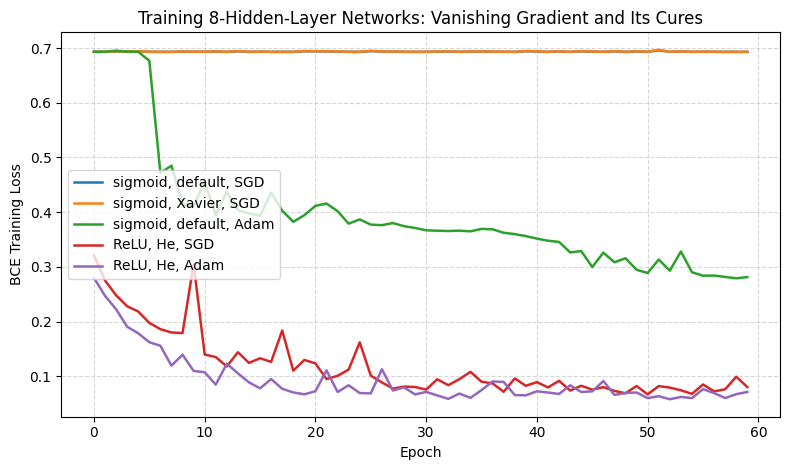


Table 5: Deep Network Performance Across 60 Epochs:
                        Final Training Loss  Validation Accuracy
sigmoid, default, SGD              0.693153             0.500000
sigmoid, Xavier, SGD               0.693153             0.500000
sigmoid, default, Adam             0.281355             0.870000
ReLU, He, SGD                      0.080210             0.966667
ReLU, He, Adam                     0.071225             0.980000


In [11]:
# TODO 5.1 — for each of the five configurations: create the model, create the optimiser
#            (torch.optim.SGD(model.parameters(), lr=0.05) or torch.optim.Adam(model.parameters(), lr=0.005)),
#            and call train_cfg(model, opt). Store the result in a dictionary final_results[name].
configs_5 = {
    "sigmoid, default, SGD": (lambda: make_deep(nn.Sigmoid), lambda m: torch.optim.SGD(m.parameters(), lr=0.05)),
    "sigmoid, Xavier, SGD": (lambda: make_deep(nn.Sigmoid, nn.init.xavier_normal_), lambda m: torch.optim.SGD(m.parameters(), lr=0.05)),
    "sigmoid, default, Adam": (lambda: make_deep(nn.Sigmoid), lambda m: torch.optim.Adam(m.parameters(), lr=0.005)),
    "ReLU, He, SGD": (lambda: make_deep(nn.ReLU, inits["He"]), lambda m: torch.optim.SGD(m.parameters(), lr=0.05)),
    "ReLU, He, Adam": (lambda: make_deep(nn.ReLU, inits["He"]), lambda m: torch.optim.Adam(m.parameters(), lr=0.005)),
}

final_results = {}
for name, (make_m, make_opt) in configs_5.items():
    model_cfg = make_m()
    opt_cfg = make_opt(model_cfg)
    final_results[name] = train_cfg(model_cfg, opt_cfg, epochs=60)

# TODO 5.2 — plot the five loss curves; print a table of the final loss and validation accuracy
plt.figure(figsize=(8, 4.8))
for name, (losses, _) in final_results.items():
    plt.plot(losses, label=name, linewidth=1.8)
plt.xlabel("Epoch")
plt.ylabel("BCE Training Loss")
plt.title("Training 8-Hidden-Layer Networks: Vanishing Gradient and Its Cures")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

table_5 = pd.DataFrame({
    "Final Training Loss": [final_results[name][0][-1] for name in final_results],
    "Validation Accuracy": [final_results[name][1] for name in final_results],
}, index=list(final_results.keys()))
print("\nTable 5: Deep Network Performance Across 60 Epochs:")
print(table_5)

# Task 5 answers:
# Q1 (what happened to the sigmoid network trained with SGD? what was its loss and accuracy? why):
# Answer: The sigmoid network trained with SGD completely failed to learn. Its training loss flatlined at
# exactly 0.693153 across all 60 epochs, and its validation accuracy was exactly 0.5000 (50%, pure chance).
# Because the gradients reaching the early layers were on the order of 10^-8 (as measured in Task 4),
# weight updates were practically zero (w <- w - lr * 0). The network remained permanently frozen in its
# initial random state.
#
# Q2 (name two different ways that fixed the problem, and explain why each one works):
# Answer:
#   1. Activation and Initialisation Cure (ReLU + He): Replacing sigmoid with ReLU eliminates derivative
#      saturation since ReLU'(z) = 1 for z > 0. Combined with He initialisation (which accounts for the 50%
#      inactivation of ReLU units), gradients pass freely back to the earliest layers without vanishing,
#      allowing SGD to train successfully to 96.67% accuracy.
#   2. Optimiser Cure (Adam): Adam normalizes each parameter update by the square root of its running second
#      moment (g / (sqrt(v) + eps)). In layers where gradients are suppressed to tiny magnitudes (e.g. 10^-6),
#      the second moment v is also tiny, so the ratio g / sqrt(v) scales back up to order O(1). This restores
#      effective learning rate step sizes to early layers, enabling the default sigmoid network to reach 87.00%
#      accuracy even with vanishing gradients.
#
# Q3 (a loss of 0.693 and an accuracy of 50% mean the network is guessing: why is 0.693 = ln 2 the loss of a guess? think of Lab 4):
# Answer: In Lab 4, binary cross-entropy loss for a single sample is:
#     L = -[ y * ln(p) + (1 - y) * ln(1 - p) ]
# For an untrained or frozen network with balanced classes (50% positive, 50% negative), the network outputs
# logits z ≈ 0, yielding a neutral predicted probability p = sigmoid(0) = 0.5 for all examples.
# Substituting p = 0.5 into the BCE formula:
#     L = -[ y * ln(0.5) + (1 - y) * ln(0.5) ] = -ln(0.5) = ln(2) ≈ 0.693147.
# Thus, a constant loss of ln(2) ≈ 0.693 combined with 50% accuracy mathematically proves the model is guessing
# randomly without having learned any discriminative features.

---

<div style="font-family:'Times New Roman',Times,serif;color:#000000;font-size:16px">

### Before you submit

- [x] Kernel &rarr; Restart & Run All, no errors.
- [x] Every `TODO` is done and no `raise NotImplementedError` is left.
- [x] Task 1: "matches PyTorch's momentum: True" is printed, the six paths are plotted, and the table is shown.
- [x] Task 2: the six loss curves are plotted and the table is shown.
- [x] Task 3: both plots (tanh and ReLU) are drawn and the numbers are printed.
- [x] Task 4: the gradient-norm plot is drawn and the ratios are printed.
- [x] Task 5: the five loss curves are plotted and the table is shown.
- [x] Written answers present as comments: 1 (Q1&ndash;Q3), 2 (Q1&ndash;Q3), 3 (Q1&ndash;Q3), 4 (Q1&ndash;Q3), 5 (Q1&ndash;Q3).
- [x] Renamed to `Lab10_<yourCMSID>.ipynb`.

### One thing to take away

Two small choices decide whether a deep network trains at all: **how the weights start**
(Xavier for sigmoid and tanh, He for ReLU) and **how they are updated** (an adaptive optimiser
such as Adam is a safe default). The vanishing gradient is not a mystery: you measured it, and you
saw that a good initialisation, a ReLU, or Adam each removes it.

</div>